# Results Analysis: Colour-Space Comparison

This notebook consolidates and analyses the results from the
RGB, HSV and grayscale experiments.

The objective is to investigate how colour-space representation
influences CNN-based artistic style classification.

The analysis focuses on overall classification performance,
class-specific performance, training behaviour and computational
cost.

All results are retrieved from the experiment artefacts saved
during the individual training and evaluation runs.

## 1. Environment setup

Mount Google Drive and initialise access to the DeepLearning project.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/DeepLearning

import sys
sys.path.insert(0, "/content/drive/MyDrive/DeepLearning")

from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from src import config, data, models, training, evaluation
from src import visualization, experiment

print("Results analysis environment ready!")

Mounted at /content/drive
/content/drive/MyDrive/DeepLearning
Results analysis environment ready!


## 2. Loading experiment results

Load the consolidated experiment summaries generated by the
RGB, HSV and grayscale experiment notebooks.

Each summary contains training information and test-set
classification metrics.

The summaries are combined into a single dataframe to support
direct comparison between colour-space representations.

### 2.1 Locate experiment summaries

Identify the saved experiment summary files for each
colour-space representation.

In [2]:
SEED = 42

summary_files = {
    "rgb": Path(config.METRICS_DIR) / f"rgb_seed{SEED}_experiment_summary.csv",
    "hsv": Path(config.METRICS_DIR) / f"hsv_seed{SEED}_experiment_summary.csv",
    "grayscale": Path(config.METRICS_DIR) / f"grayscale_seed{SEED}_experiment_summary.csv"
}

print("EXPERIMENT SUMMARY FILES")
print("-" * 50)

for color_space, file_path in summary_files.items():
    print(f"{color_space.upper()}: {file_path.exists()}")

    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing experiment summary: {file_path}"
        )

EXPERIMENT SUMMARY FILES
--------------------------------------------------
RGB: True
HSV: True
GRAYSCALE: True


### 2.2 Load and combine experiment summaries

Load the three experiment summaries and combine them into
a single dataframe.

The resulting dataframe provides one row per colour-space
experiment and serves as the primary source for the comparative
analysis.

In [3]:
experiment_results = pd.concat(
    [
        pd.read_csv(file_path)
        for file_path in summary_files.values()
    ],
    ignore_index=True
)

experiment_results = experiment_results.set_index("color_space").loc[
    ["rgb", "hsv", "grayscale"]
].reset_index()

display(experiment_results)

,color_space,seed,epochs_completed,best_epoch,training_time_seconds,parameter_count,accuracy,macro_precision,macro_recall,macro_f1,test_loss,test_accuracy
0,rgb,42,30,30,136.728655,110147,0.800000,0.809091,0.800000,0.803091,0.437413,0.800000
1,hsv,42,30,30,190.902518,110147,0.700000,0.695604,0.700000,0.688747,0.645840,0.700000
2,grayscale,42,30,27,124.974325,110147,0.966667,0.969697,0.966667,0.966583,0.361908,0.966667


### 2.3 Validate experiment results

Verify that all three colour-space experiments are represented
and that they use the same random seed and CNN parameter count.

This check ensures that the expected experiment records have
been loaded before proceeding with comparative analysis.

In [4]:
expected_color_spaces = ["rgb", "hsv", "grayscale"]

assert experiment_results["color_space"].tolist() == expected_color_spaces

assert experiment_results["seed"].nunique() == 1
assert experiment_results["seed"].iloc[0] == SEED

assert experiment_results["parameter_count"].nunique() == 1
assert experiment_results["parameter_count"].iloc[0] == 110147

print("EXPERIMENT VALIDATION")
print("-" * 45)
print("Colour spaces:", experiment_results["color_space"].tolist())
print("Random seed:", experiment_results["seed"].iloc[0])
print("Model parameters:", experiment_results["parameter_count"].iloc[0])

print("\nAll experiment summaries loaded and validated successfully.")

EXPERIMENT VALIDATION
---------------------------------------------
Colour spaces: ['rgb', 'hsv', 'grayscale']
Random seed: 42
Model parameters: 110147

All experiment summaries loaded and validated successfully.


### 2.4 Inspect available metrics

Inspect the columns available in the combined experiment
summary.

These include the training metadata and classification
metrics used in the subsequent comparison.

In [5]:
print("AVAILABLE RESULT COLUMNS")
print("-" * 45)

for column in experiment_results.columns:
    print(column)

AVAILABLE RESULT COLUMNS
---------------------------------------------
color_space
seed
epochs_completed
best_epoch
training_time_seconds
parameter_count
accuracy
macro_precision
macro_recall
macro_f1
test_loss
test_accuracy


## 3. Overall performance comparison

Compare the classification performance of the three colour-space
representations: RGB, HSV and grayscale.

The comparison focuses on accuracy, macro-averaged precision,
recall and F1-score.

These metrics provide complementary perspectives on the
classification performance of each representation.

### 3.1 Classification performance comparison

Visualise the classification metrics for each colour-space
experiment.

Macro-averaged metrics are used to give equal importance to
each artistic style when evaluating overall performance.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/classification_performance_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/classification_performance_comparison_seed42.pdf


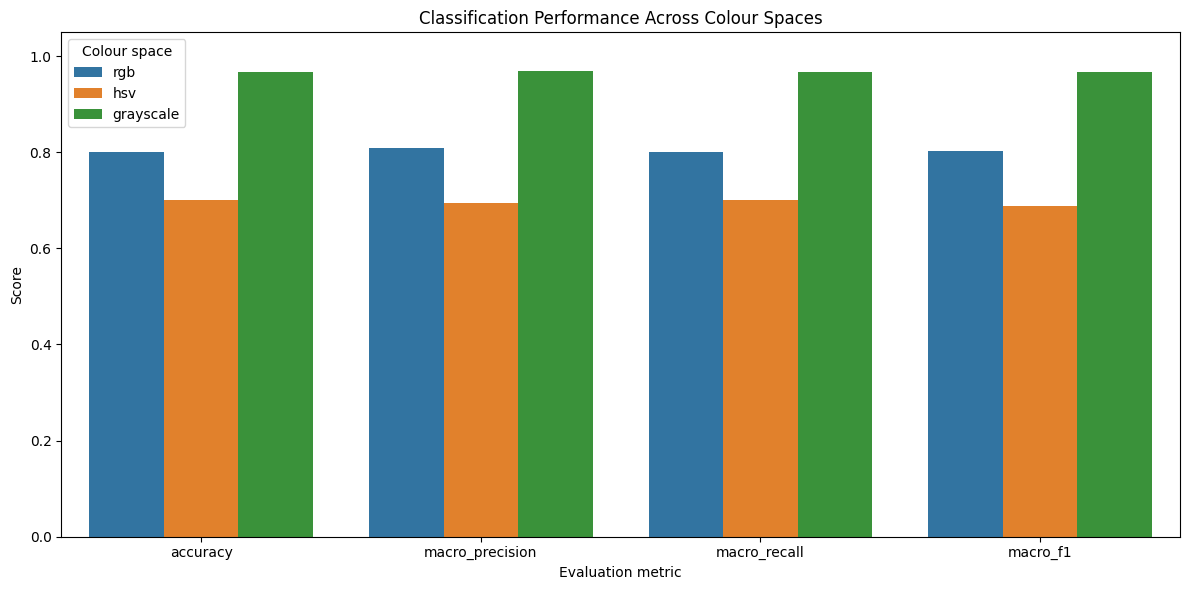

In [6]:
performance_metrics = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]

performance_comparison = experiment_results[
    ["color_space"] + performance_metrics
].melt(
    id_vars="color_space",
    var_name="metric",
    value_name="score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_comparison,
    x="metric",
    y="score",
    hue="color_space"
)

plt.title("Classification Performance Across Colour Spaces")
plt.xlabel("Evaluation metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(title="Colour space")
plt.tight_layout()

fig = plt.gcf()

visualization.save_figure(
    fig,
    "classification_performance_comparison_seed42"
)

plt.show()
plt.close(fig)

### 3.2 Test accuracy and loss comparison

Compare test accuracy and test loss across the three
colour-space representations.

Accuracy measures the proportion of correctly classified
images, while test loss measures the model's prediction error
according to the categorical crossentropy objective.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/test_accuracy_loss_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/test_accuracy_loss_comparison_seed42.pdf


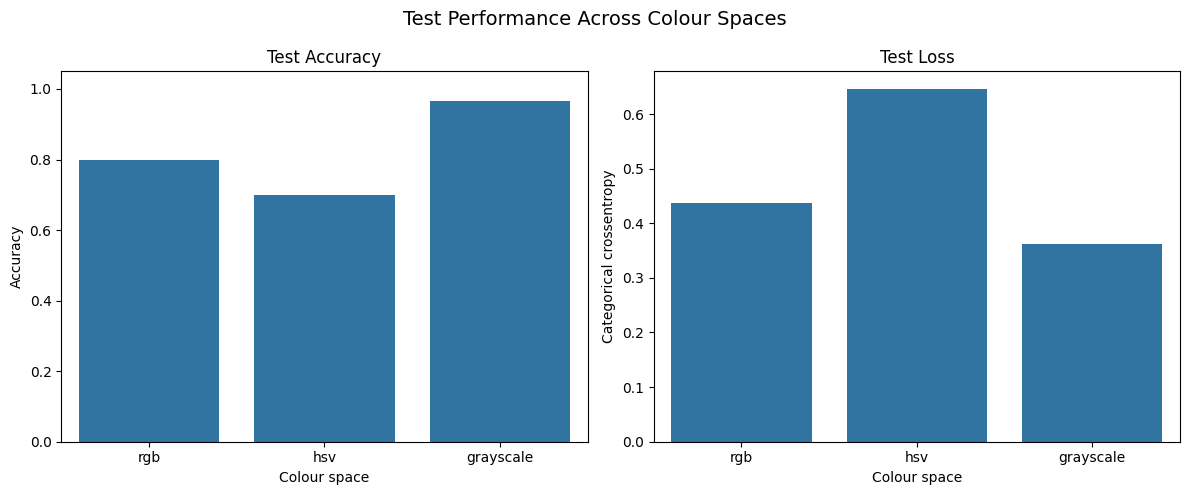

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=experiment_results,
    x="color_space",
    y="test_accuracy",
    ax=axes[0]
)

axes[0].set_title("Test Accuracy")
axes[0].set_xlabel("Colour space")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)

sns.barplot(
    data=experiment_results,
    x="color_space",
    y="test_loss",
    ax=axes[1]
)

axes[1].set_title("Test Loss")
axes[1].set_xlabel("Colour space")
axes[1].set_ylabel("Categorical crossentropy")

fig.suptitle("Test Performance Across Colour Spaces", fontsize=14)
plt.tight_layout()

visualization.save_figure(
    fig,
    "test_accuracy_loss_comparison_seed42"
)

plt.show()
plt.close(fig)

### 3.3 Relative performance differences

Calculate the absolute differences in test accuracy and
macro F1-score between HSV and grayscale compared with RGB.

The differences are expressed in percentage points to make
the comparison easier to interpret.

In [8]:
rgb_baseline = experiment_results.set_index("color_space").loc["rgb"]

performance_differences = experiment_results[
    ["color_space", "test_accuracy", "macro_f1"]
].copy()

performance_differences["accuracy_difference_pp"] = (
    performance_differences["test_accuracy"] - rgb_baseline["test_accuracy"]
) * 100

performance_differences["f1_difference_pp"] = (
    performance_differences["macro_f1"] - rgb_baseline["macro_f1"]
) * 100

display(performance_differences)

,color_space,test_accuracy,macro_f1,accuracy_difference_pp,f1_difference_pp
0,rgb,0.800000,0.803091,0.000000,0.000000
1,hsv,0.700000,0.688747,-10.000002,-11.434426
2,grayscale,0.966667,0.966583,16.666663,16.349206


In [9]:
comparison_path = (
    Path(config.TABLES_DIR) /
    "classification_performance_comparison_seed42.csv"
)

config.TABLES_DIR.mkdir(parents=True, exist_ok=True)

performance_differences.to_csv(comparison_path, index=False)

print("Saved comparison table:", comparison_path)

Saved comparison table: /content/drive/MyDrive/DeepLearning/outputs/tables/classification_performance_comparison_seed42.csv


## 4. Per-class performance analysis

Investigate classification performance separately for Monet,
Picasso and Van Gogh.

Class-specific precision, recall and F1-score are examined
to identify differences in how each colour-space representation
distinguishes between the artistic styles.

Confusion matrices are also used to investigate the distribution
of correct and incorrect predictions.

### 4.1 Load classification reports

Load the saved classification reports from the RGB, HSV and
grayscale experiments.

These reports contain precision, recall, F1-score and support
for each artistic style.

In [10]:
classification_reports = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    report_path = (
        Path(config.METRICS_DIR) /
        f"{color_space}_seed{SEED}_classification_report.csv"
    )

    assert report_path.exists(), f"Missing report: {report_path}"

    classification_reports[color_space] = pd.read_csv(
        report_path,
        index_col=0
    )

    print(f"\n{color_space.upper()} CLASSIFICATION REPORT")
    print("-" * 45)

    display(classification_reports[color_space])


RGB CLASSIFICATION REPORT
---------------------------------------------


,precision,recall,f1-score,support
monet,0.727273,0.8,0.761905,10.0
picasso,1.000000,0.9,0.947368,10.0
vangogh,0.700000,0.7,0.700000,10.0
accuracy,0.800000,0.8,0.800000,0.8
macro avg,0.809091,0.8,0.803091,30.0
weighted avg,0.809091,0.8,0.803091,30.0



HSV CLASSIFICATION REPORT
---------------------------------------------


,precision,recall,f1-score,support
monet,0.615385,0.8,0.695652,10.0
picasso,0.900000,0.9,0.900000,10.0
vangogh,0.571429,0.4,0.470588,10.0
accuracy,0.700000,0.7,0.700000,0.7
macro avg,0.695604,0.7,0.688747,30.0
weighted avg,0.695604,0.7,0.688747,30.0



GRAYSCALE CLASSIFICATION REPORT
---------------------------------------------


,precision,recall,f1-score,support
monet,1.000000,0.900000,0.947368,10.000000
picasso,1.000000,1.000000,1.000000,10.000000
vangogh,0.909091,1.000000,0.952381,10.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.969697,0.966667,0.966583,30.000000
weighted avg,0.969697,0.966667,0.966583,30.000000


### 4.2 Compare class-specific metrics

Extract precision, recall and F1-score for each artistic style
from the classification reports.

The comparison focuses on the three target classes and excludes
the aggregate macro and weighted averages.

In [11]:
class_metrics = []

for color_space, report in classification_reports.items():

    for artist in config.CLASSES:

        if artist not in report.index:
            raise ValueError(
                f"Class '{artist}' not found in {color_space} report. "
                f"Available labels: {report.index.tolist()}"
            )

        class_metrics.append({
            "color_space": color_space,
            "artist": artist,
            "precision": report.loc[artist, "precision"],
            "recall": report.loc[artist, "recall"],
            "f1_score": report.loc[artist, "f1-score"],
            "support": report.loc[artist, "support"]
        })

class_metrics_df = pd.DataFrame(class_metrics)

display(class_metrics_df)

,color_space,artist,precision,recall,f1_score,support
0,rgb,monet,0.727273,0.8,0.761905,10.0
1,rgb,picasso,1.000000,0.9,0.947368,10.0
2,rgb,vangogh,0.700000,0.7,0.700000,10.0
3,hsv,monet,0.615385,0.8,0.695652,10.0
4,hsv,picasso,0.900000,0.9,0.900000,10.0
5,hsv,vangogh,0.571429,0.4,0.470588,10.0
6,grayscale,monet,1.000000,0.9,0.947368,10.0
7,grayscale,picasso,1.000000,1.0,1.000000,10.0
8,grayscale,vangogh,0.909091,1.0,0.952381,10.0


### 4.3 Class-specific F1-score comparison

Visualise the F1-score achieved for each artistic style
across the three colour-space representations.

This comparison helps identify whether the overall performance
differences are consistent across classes or concentrated
in particular artistic styles.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_specific_f1_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_specific_f1_comparison_seed42.pdf


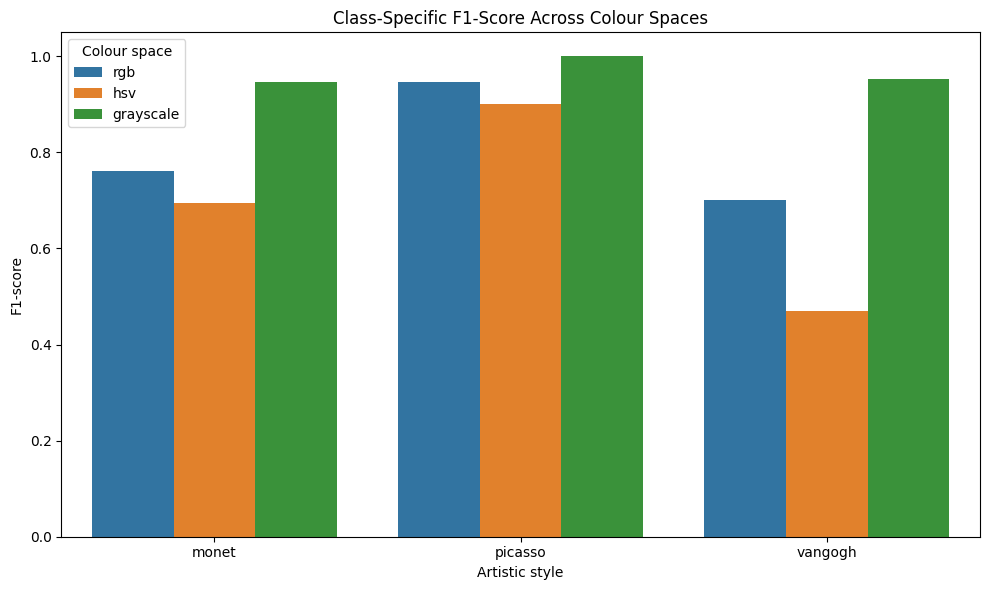

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=class_metrics_df,
    x="artist",
    y="f1_score",
    hue="color_space",
    ax=ax
)

ax.set_title("Class-Specific F1-Score Across Colour Spaces")
ax.set_xlabel("Artistic style")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.05)
ax.legend(title="Colour space")

plt.tight_layout()

visualization.save_figure(
    fig,
    "class_specific_f1_comparison_seed42"
)

plt.show()
plt.close(fig)

### 4.4 Load confusion matrices

Load the saved confusion matrices from the RGB, HSV and
grayscale experiments.

The matrices provide a class-by-class breakdown of correct
predictions and misclassifications.

In [13]:
confusion_matrices = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    matrix_path = (
        Path(config.METRICS_DIR) /
        f"{color_space}_seed{SEED}_confusion_matrix.csv"
    )

    assert matrix_path.exists(), f"Missing matrix: {matrix_path}"

    matrix_df = pd.read_csv(matrix_path, index_col=0)

    matrix_df = matrix_df.loc[
        config.CLASSES, config.CLASSES
    ]

    confusion_matrices[color_space] = matrix_df

    print(f"\n{color_space.upper()} CONFUSION MATRIX")
    display(matrix_df)


RGB CONFUSION MATRIX


,monet,picasso,vangogh
monet,8,0,2
picasso,0,9,1
vangogh,3,0,7



HSV CONFUSION MATRIX


,monet,picasso,vangogh
monet,8,0,2
picasso,0,9,1
vangogh,5,1,4



GRAYSCALE CONFUSION MATRIX


,monet,picasso,vangogh
monet,9,0,1
picasso,0,10,0
vangogh,0,0,10


### 4.5 Confusion matrix comparison

Visualise the confusion matrices for all three colour-space
representations side by side.

Rows represent actual artistic styles and columns represent
predicted artistic styles.

The diagonal represents correct classifications, while
off-diagonal values indicate misclassifications.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_comparison_seed42.pdf


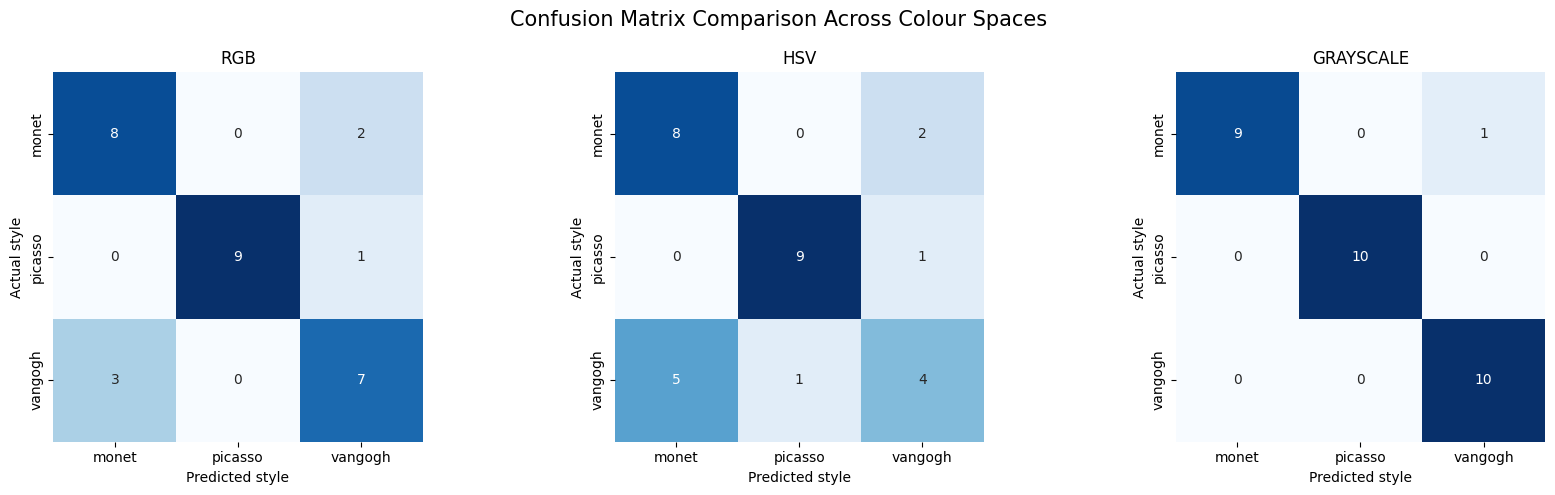

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, color_space in zip(
    axes, ["rgb", "hsv", "grayscale"]
):

    sns.heatmap(
        confusion_matrices[color_space],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=config.CLASSES,
        yticklabels=config.CLASSES,
        ax=ax
    )

    ax.set_title(color_space.upper())
    ax.set_xlabel("Predicted style")
    ax.set_ylabel("Actual style")

fig.suptitle(
    "Confusion Matrix Comparison Across Colour Spaces",
    fontsize=15
)

plt.tight_layout()

visualization.save_figure(
    fig,
    "confusion_matrix_comparison_seed42"
)

plt.show()
plt.close(fig)

### 4.6 Class-specific misclassification analysis

Calculate the number of correct and incorrect predictions
for each artistic style and colour-space representation.

This provides a numerical comparison of the classification
errors observed in the confusion matrices.

In [15]:
misclassification_results = []

for color_space, matrix in confusion_matrices.items():

    for artist in config.CLASSES:

        correct = int(matrix.loc[artist, artist])
        total = int(matrix.loc[artist].sum())
        incorrect = total - correct

        misclassification_results.append({
            "color_space": color_space,
            "artist": artist,
            "correct_predictions": correct,
            "incorrect_predictions": incorrect,
            "total_images": total
        })

misclassification_df = pd.DataFrame(
    misclassification_results
)

display(misclassification_df)

,color_space,artist,correct_predictions,incorrect_predictions,total_images
0,rgb,monet,8,2,10
1,rgb,picasso,9,1,10
2,rgb,vangogh,7,3,10
3,hsv,monet,8,2,10
4,hsv,picasso,9,1,10
5,hsv,vangogh,4,6,10
6,grayscale,monet,9,1,10
7,grayscale,picasso,10,0,10
8,grayscale,vangogh,10,0,10


## 5. Training behaviour and computational cost

Compare the training behaviour and computational cost of the
three colour-space experiments.

Training histories are examined to investigate convergence,
training and validation performance, and potential overfitting.

Training duration and the number of completed epochs are
also compared.

### 5.1 Load training histories

Load the recorded training histories from the RGB, HSV and
grayscale experiments.

Each history contains training and validation accuracy and
loss across epochs.

In [16]:
training_histories = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    history_path = (
        Path(config.METRICS_DIR) /
        f"{color_space}_seed{SEED}_history.csv"
    )

    assert history_path.exists(), f"Missing history: {history_path}"

    training_histories[color_space] = pd.read_csv(history_path)

    print(
        f"{color_space.upper()}: "
        f"{len(training_histories[color_space])} epochs"
    )

print("\nAll training histories loaded successfully.")

RGB: 30 epochs
HSV: 30 epochs
GRAYSCALE: 30 epochs

All training histories loaded successfully.


### 5.2 Training and validation accuracy

Compare training and validation accuracy across the three
colour-space experiments.

The curves illustrate how classification performance develops
during training and how well the models generalise to the
validation dataset.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_behaviour_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_behaviour_comparison_seed42.pdf


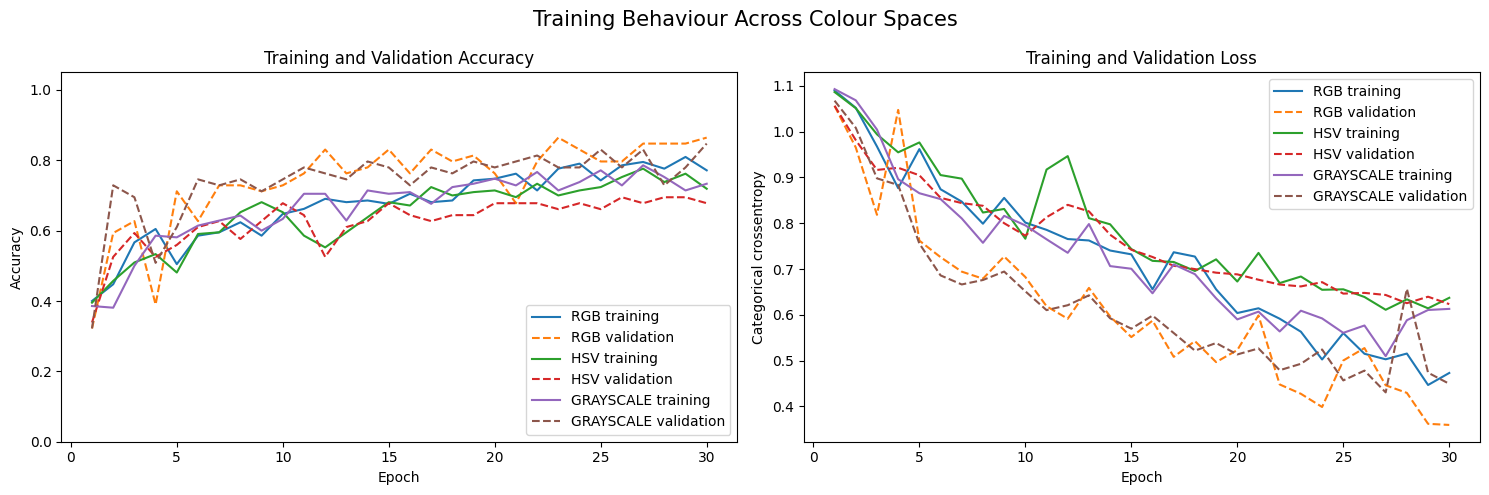

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for color_space, history in training_histories.items():

    epochs = range(1, len(history) + 1)

    axes[0].plot(
        epochs,
        history["accuracy"],
        label=f"{color_space.upper()} training"
    )

    axes[0].plot(
        epochs,
        history["val_accuracy"],
        linestyle="--",
        label=f"{color_space.upper()} validation"
    )

axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].legend()

for color_space, history in training_histories.items():

    epochs = range(1, len(history) + 1)

    axes[1].plot(
        epochs,
        history["loss"],
        label=f"{color_space.upper()} training"
    )

    axes[1].plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"{color_space.upper()} validation"
    )

axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical crossentropy")
axes[1].legend()

fig.suptitle("Training Behaviour Across Colour Spaces", fontsize=15)

plt.tight_layout()

visualization.save_figure(
    fig,
    "training_behaviour_comparison_seed42"
)

plt.show()
plt.close(fig)

### 5.3 Convergence analysis

Compare the epoch at which each model achieved its lowest
validation loss and highest validation accuracy.

These values provide an indication of when the models
achieved their strongest validation performance.

In [18]:
convergence_results = []

for color_space, history in training_histories.items():

    best_loss_epoch = history["val_loss"].idxmin()
    best_accuracy_epoch = history["val_accuracy"].idxmax()

    convergence_results.append({
        "color_space": color_space,
        "epochs_completed": len(history),
        "best_validation_loss_epoch": best_loss_epoch + 1,
        "best_validation_accuracy_epoch": best_accuracy_epoch + 1,
        "best_validation_loss": history.loc[best_loss_epoch, "val_loss"],
        "best_validation_accuracy": history.loc[
            best_accuracy_epoch, "val_accuracy"
        ]
    })

convergence_df = pd.DataFrame(convergence_results)

display(convergence_df)

,color_space,epochs_completed,best_validation_loss_epoch,best_validation_accuracy_epoch,best_validation_loss,best_validation_accuracy
0,rgb,30,30,23,0.359476,0.864407
1,hsv,30,30,26,0.623388,0.694915
2,grayscale,30,27,30,0.430570,0.847458


### 5.4 Training duration comparison

Compare the recorded training duration for each colour-space
experiment.

Training duration is used as an approximate indicator of
computational cost.

The comparison should be interpreted in the context of the
shared Google Colab runtime environment.

In [19]:
training_cost = experiment_results[
    [
        "color_space",
        "training_time_seconds",
        "epochs_completed",
        "parameter_count"
    ]
].copy()

training_cost["training_time_minutes"] = (
    training_cost["training_time_seconds"] / 60
)

display(training_cost)

,color_space,training_time_seconds,epochs_completed,parameter_count,training_time_minutes
0,rgb,136.728655,30,110147,2.278811
1,hsv,190.902518,30,110147,3.181709
2,grayscale,124.974325,30,110147,2.082905


## 5.5 Visualise training duration


Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_duration_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_duration_comparison_seed42.pdf


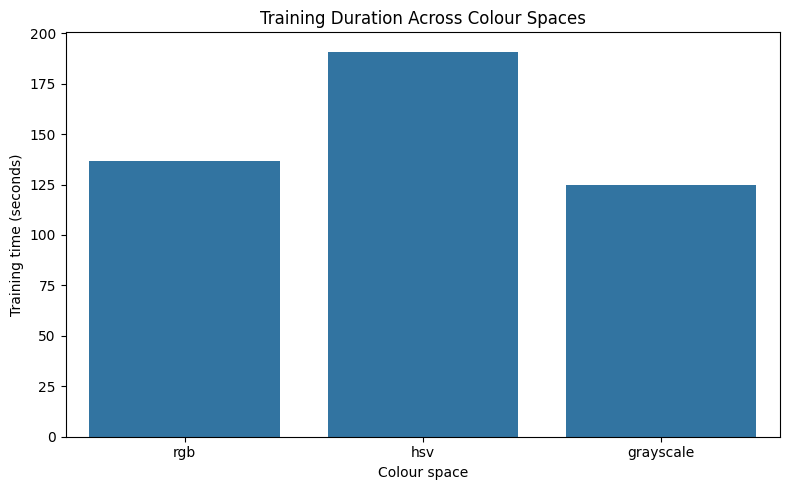

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=training_cost,
    x="color_space",
    y="training_time_seconds",
    ax=ax
)

ax.set_title("Training Duration Across Colour Spaces")
ax.set_xlabel("Colour space")
ax.set_ylabel("Training time (seconds)")

plt.tight_layout()

visualization.save_figure(
    fig,
    "training_duration_comparison_seed42"
)

plt.show()
plt.close(fig)

## 5.6 Save training comparison results

In [21]:
convergence_path = (
    Path(config.TABLES_DIR) /
    "convergence_comparison_seed42.csv"
)

training_cost_path = (
    Path(config.TABLES_DIR) /
    "training_cost_comparison_seed42.csv"
)

convergence_df.to_csv(convergence_path, index=False)
training_cost.to_csv(training_cost_path, index=False)

print("Saved convergence comparison:", convergence_path)
print("Saved training cost comparison:", training_cost_path)

Saved convergence comparison: /content/drive/MyDrive/DeepLearning/outputs/tables/convergence_comparison_seed42.csv
Saved training cost comparison: /content/drive/MyDrive/DeepLearning/outputs/tables/training_cost_comparison_seed42.csv


## 6. Prediction confidence and error analysis

Investigate the individual predictions produced by the three
colour-space models.

The analysis focuses on prediction confidence, correctly
classified examples and misclassified examples.

This provides additional insight into model behaviour beyond
aggregate classification metrics.

### 6.1 Load prediction results

Load the saved prediction files generated during the evaluation
of the RGB, HSV and grayscale models.

Inspect their columns and structure before performing
confidence and error analysis.

In [22]:
prediction_results = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    prediction_path = (
        Path(config.METRICS_DIR) /
        f"{color_space}_seed{SEED}_predictions.csv"
    )

    assert prediction_path.exists(), (
        f"Missing predictions: {prediction_path}"
    )

    predictions = pd.read_csv(prediction_path)

    prediction_results[color_space] = predictions

    print(f"\n{color_space.upper()} PREDICTIONS")
    print("-" * 45)

    print("Shape:", predictions.shape)
    print("Columns:", predictions.columns.tolist())

    display(predictions.head())


RGB PREDICTIONS
---------------------------------------------
Shape: (30, 2)
Columns: ['true_label', 'predicted_label']


,true_label,predicted_label
0,monet,monet
1,monet,vangogh
2,monet,vangogh
3,monet,monet
4,monet,monet



HSV PREDICTIONS
---------------------------------------------
Shape: (30, 2)
Columns: ['true_label', 'predicted_label']


,true_label,predicted_label
0,monet,monet
1,monet,vangogh
2,monet,vangogh
3,monet,monet
4,monet,monet



GRAYSCALE PREDICTIONS
---------------------------------------------
Shape: (30, 2)
Columns: ['true_label', 'predicted_label']


,true_label,predicted_label
0,monet,monet
1,monet,monet
2,monet,monet
3,monet,monet
4,monet,vangogh


### 6.2 Prediction error analysis

Compare the predicted labels against the true labels for
each colour-space representation.

Identify correctly classified and misclassified examples
and calculate the corresponding error rates.

This analysis provides an example-level perspective on
classification performance.

In [23]:
prediction_analysis = {}

for color_space, predictions in prediction_results.items():

    results = predictions.copy()

    results["correct"] = (
        results["true_label"] == results["predicted_label"]
    )

    results["error"] = ~results["correct"]

    prediction_analysis[color_space] = results

    print(f"\n{color_space.upper()} PREDICTION ANALYSIS")
    print("-" * 45)

    print("Correct predictions:", results["correct"].sum())
    print("Incorrect predictions:", results["error"].sum())
    print(
        "Error rate:",
        f"{results['error'].mean() * 100:.2f}%"
    )


RGB PREDICTION ANALYSIS
---------------------------------------------
Correct predictions: 24
Incorrect predictions: 6
Error rate: 20.00%

HSV PREDICTION ANALYSIS
---------------------------------------------
Correct predictions: 21
Incorrect predictions: 9
Error rate: 30.00%

GRAYSCALE PREDICTION ANALYSIS
---------------------------------------------
Correct predictions: 29
Incorrect predictions: 1
Error rate: 3.33%


### 6.3 Class-specific error analysis

Examine the number of misclassified images for each artistic
style across the three colour-space representations.

This comparison identifies which styles contribute most
to classification errors.

In [24]:
class_error_results = []

for color_space, results in prediction_analysis.items():

    for artist in config.CLASSES:

        artist_results = results[
            results["true_label"] == artist
        ]

        class_error_results.append({
            "color_space": color_space,
            "artist": artist,
            "correct": int(artist_results["correct"].sum()),
            "incorrect": int(artist_results["error"].sum()),
            "error_rate": artist_results["error"].mean()
        })

class_error_df = pd.DataFrame(class_error_results)

display(class_error_df)

,color_space,artist,correct,incorrect,error_rate
0,rgb,monet,8,2,0.2
1,rgb,picasso,9,1,0.1
2,rgb,vangogh,7,3,0.3
3,hsv,monet,8,2,0.2
4,hsv,picasso,9,1,0.1
5,hsv,vangogh,4,6,0.6
6,grayscale,monet,9,1,0.1
7,grayscale,picasso,10,0,0.0
8,grayscale,vangogh,10,0,0.0


### 6.4 Prediction agreement across colour spaces

Compare the predictions made by the three models for each
test-set image.

This analysis identifies examples where the models agree
and examples where their predictions differ.

The comparison is based on the shared ordering of the
unshuffled test dataset.

In [25]:
prediction_agreement = pd.DataFrame({
    "true_label": prediction_results["rgb"]["true_label"],
    "rgb_prediction": prediction_results["rgb"]["predicted_label"],
    "hsv_prediction": prediction_results["hsv"]["predicted_label"],
    "grayscale_prediction": prediction_results["grayscale"]["predicted_label"]
})

assert (
    prediction_results["rgb"]["true_label"].equals(
        prediction_results["hsv"]["true_label"]
    )
)

assert (
    prediction_results["rgb"]["true_label"].equals(
        prediction_results["grayscale"]["true_label"]
    )
)

prediction_agreement["all_agree"] = (
    prediction_agreement[
        ["rgb_prediction", "hsv_prediction", "grayscale_prediction"]
    ].nunique(axis=1) == 1
)

prediction_agreement["all_correct"] = (
    prediction_agreement["rgb_prediction"]
    == prediction_agreement["true_label"]
) & (
    prediction_agreement["hsv_prediction"]
    == prediction_agreement["true_label"]
) & (
    prediction_agreement["grayscale_prediction"]
    == prediction_agreement["true_label"]
)

display(prediction_agreement.head(15))

print("All three models agree:", prediction_agreement["all_agree"].sum())
print("All three models classify correctly:", prediction_agreement["all_correct"].sum())

,true_label,rgb_prediction,hsv_prediction,grayscale_prediction,all_agree,all_correct
0,monet,monet,monet,monet,True,True
1,monet,vangogh,vangogh,monet,False,False
2,monet,vangogh,vangogh,monet,False,False
3,monet,monet,monet,monet,True,True
4,monet,monet,monet,vangogh,False,False
5,monet,monet,monet,monet,True,True
6,monet,monet,monet,monet,True,True
7,monet,monet,monet,monet,True,True
8,monet,monet,monet,monet,True,True
9,monet,monet,monet,monet,True,True


All three models agree: 20
All three models classify correctly: 20


### 6.5 Inspect disagreements between models

Identify test examples for which the three models produce
different predictions.

These examples are particularly useful for investigating
how colour-space representation influences classification.

In [26]:
disagreements = prediction_agreement[
    ~prediction_agreement["all_agree"]
]

display(disagreements)

print("Number of examples with differing predictions:", len(disagreements))

,true_label,rgb_prediction,hsv_prediction,grayscale_prediction,all_agree,all_correct
1,monet,vangogh,vangogh,monet,False,False
2,monet,vangogh,vangogh,monet,False,False
4,monet,monet,monet,vangogh,False,False
15,picasso,vangogh,vangogh,picasso,False,False
20,vangogh,vangogh,monet,vangogh,False,False
22,vangogh,vangogh,monet,vangogh,False,False
23,vangogh,vangogh,monet,vangogh,False,False
24,vangogh,monet,picasso,vangogh,False,False
25,vangogh,monet,monet,vangogh,False,False
26,vangogh,monet,monet,vangogh,False,False


Number of examples with differing predictions: 10


## 7. Prediction confidence and calibration

Investigate the confidence and calibration of the three
colour-space models.

Softmax probabilities are used to examine the confidence
assigned to individual predictions.

The analysis distinguishes between correctly and incorrectly
classified examples and evaluates whether predicted confidence
corresponds to observed classification accuracy.

In [39]:
# Recalculate calibration metrics for all colour spaces

def calculate_calibration_metrics(probabilities, true_labels, n_bins=5):

    predicted_indices = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    correct = predicted_indices == true_labels

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0
    calibration_bins = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = (confidence >= lower) & (confidence <= upper)
        else:
            mask = (confidence >= lower) & (confidence < upper)

        if np.any(mask):

            bin_accuracy = correct[mask].mean()
            bin_confidence = confidence[mask].mean()
            bin_size = mask.sum()

            ece += (
                bin_size / len(confidence)
            ) * abs(bin_accuracy - bin_confidence)

            calibration_bins.append({
                "bin_lower": lower,
                "bin_upper": upper,
                "mean_confidence": bin_confidence,
                "accuracy": bin_accuracy,
                "count": bin_size
            })

    one_hot_labels = tf.keras.utils.to_categorical(
        true_labels,
        num_classes=config.NUM_CLASSES
    )

    brier_score = np.mean(
        np.sum((probabilities - one_hot_labels) ** 2, axis=1)
    )

    return {
        "ece": ece,
        "brier_score": brier_score,
        "bins": pd.DataFrame(calibration_bins)
    }


# Calculate metrics for each colour space

calibration_results = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    true_labels = np.array([
        config.CLASSES.index(label)
        for label in prediction_results[color_space]["true_label"]
    ])

    calibration_results[color_space] = calculate_calibration_metrics(
        probability_results[color_space],
        true_labels
    )


# Create comparison DataFrame

calibration_summary_df = pd.DataFrame([
    {
        "color_space": color_space,
        "ece": results["ece"],
        "brier_score": results["brier_score"]
    }
    for color_space, results in calibration_results.items()
])

display(calibration_summary_df.round(4))

,color_space,ece,brier_score
0,rgb,0.131,0.2507
1,hsv,0.145,0.3825
2,grayscale,0.241,0.1998


### 7.1 Overall prediction confidence

Calculate the mean maximum softmax probability for each
colour-space representation.

Compare confidence across all predictions, correctly
classified predictions and incorrectly classified predictions.

In [40]:
probability_results = {}
confidence_results = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    print(f"Loading {color_space.upper()} model...")

    # Load the corresponding test dataset
    _, _, current_test_dataset = data.load_datasets(
        color_space=color_space,
        seed=SEED
    )

    # Load the best saved model
    model_path = (
        Path(config.MODELS_DIR) /
        f"{color_space}_seed{SEED}.keras"
    )

    assert model_path.exists(), f"Missing model: {model_path}"

    saved_model = tf.keras.models.load_model(model_path)

    # Retrieve prediction probabilities
    probabilities = saved_model.predict(
        current_test_dataset,
        verbose=0
    )

    probability_results[color_space] = probabilities

    # Extract predictions and confidence
    predicted_indices = np.argmax(probabilities, axis=1)
    predicted_labels = [
        config.CLASSES[index] for index in predicted_indices
    ]

    confidence = np.max(probabilities, axis=1)

    original_predictions = prediction_results[color_space]

    assert predicted_labels == original_predictions[
        "predicted_label"
    ].tolist(), f"Prediction mismatch for {color_space}"

    confidence_results[color_space] = pd.DataFrame({
        "true_label": original_predictions["true_label"],
        "predicted_label": predicted_labels,
        "confidence": confidence,
        "correct": (
            np.array(predicted_labels)
            == original_predictions["true_label"].values
        )
    })

    print(f"{color_space.upper()} probabilities retrieved.")

Loading RGB model...
Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
RGB probabilities retrieved.
Loading HSV model...
Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
HSV probabilities retrieved.
Loading GRAYSCALE model...
Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
GRAYSCALE probabilities retrieved.


In [41]:
confidence_summary = []

for color_space, results in confidence_results.items():

    confidence_summary.append({
        "color_space": color_space,
        "mean_confidence": results["confidence"].mean(),
        "correct_confidence": results.loc[
            results["correct"], "confidence"
        ].mean(),
        "incorrect_confidence": results.loc[
            ~results["correct"], "confidence"
        ].mean(),
        "accuracy": results["correct"].mean()
    })

confidence_summary_df = pd.DataFrame(confidence_summary)

display(confidence_summary_df)

,color_space,mean_confidence,correct_confidence,incorrect_confidence,accuracy
0,rgb,0.813284,0.856428,0.640708,0.800000
1,hsv,0.711732,0.762339,0.593651,0.700000
2,grayscale,0.725686,0.731881,0.546034,0.966667


### 7.2 Prediction confidence distributions

Visualise the distribution of maximum softmax probabilities
for each colour-space model.

The distributions are separated into correct and incorrect
predictions to investigate whether confidence differs
depending on classification correctness.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/prediction_confidence_comparison_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/prediction_confidence_comparison_seed42.pdf


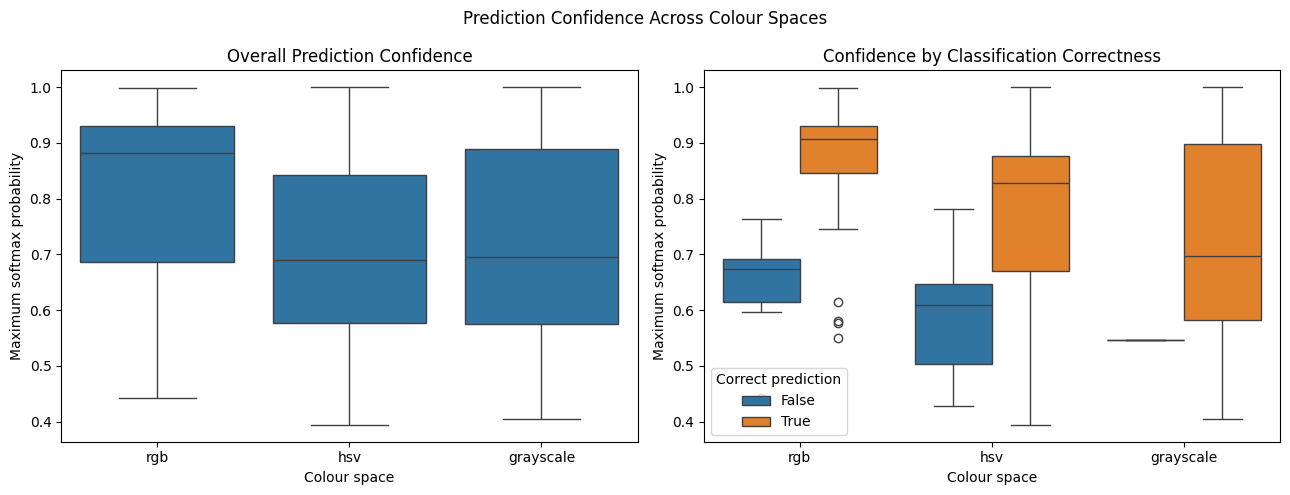

In [42]:
confidence_plot_data = pd.concat(
    [
        results.assign(color_space=color_space)
        for color_space, results in confidence_results.items()
    ],
    ignore_index=True
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=confidence_plot_data,
    x="color_space",
    y="confidence",
    ax=axes[0]
)

axes[0].set_title("Overall Prediction Confidence")
axes[0].set_xlabel("Colour space")
axes[0].set_ylabel("Maximum softmax probability")

sns.boxplot(
    data=confidence_plot_data,
    x="color_space",
    y="confidence",
    hue="correct",
    ax=axes[1]
)

axes[1].set_title("Confidence by Classification Correctness")
axes[1].set_xlabel("Colour space")
axes[1].set_ylabel("Maximum softmax probability")
axes[1].legend(title="Correct prediction")

fig.suptitle("Prediction Confidence Across Colour Spaces")
plt.tight_layout()

visualization.save_figure(
    fig,
    "prediction_confidence_comparison_seed42"
)

plt.show()
plt.close(fig)

### 7.3 Calibration analysis

Evaluate the relationship between prediction confidence
and observed classification accuracy.

Expected Calibration Error (ECE) measures the weighted
difference between average confidence and observed accuracy
within confidence intervals.

The multiclass Brier score measures the squared difference
between predicted class probabilities and one-hot encoded
true labels. Lower values indicate better probabilistic
prediction performance.

In [43]:
def calculate_calibration_metrics(probabilities, true_labels, n_bins=5):

    predicted_indices = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    correct = predicted_indices == true_labels

    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0
    calibration_bins = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = (confidence >= lower) & (confidence <= upper)
        else:
            mask = (confidence >= lower) & (confidence < upper)

        if np.any(mask):

            bin_accuracy = correct[mask].mean()
            bin_confidence = confidence[mask].mean()
            bin_size = mask.sum()

            ece += (
                bin_size / len(confidence)
            ) * abs(bin_accuracy - bin_confidence)

            calibration_bins.append({
                "bin_lower": lower,
                "bin_upper": upper,
                "mean_confidence": bin_confidence,
                "accuracy": bin_accuracy,
                "count": bin_size
            })

    one_hot_labels = tf.keras.utils.to_categorical(
        true_labels,
        num_classes=config.NUM_CLASSES
    )

    brier_score = np.mean(
        np.sum((probabilities - one_hot_labels) ** 2, axis=1)
    )

    return {
        "ece": ece,
        "brier_score": brier_score,
        "bins": pd.DataFrame(calibration_bins)
    }

In [44]:
calibration_results = {}

for color_space in ["rgb", "hsv", "grayscale"]:

    true_labels = np.array([
        config.CLASSES.index(label)
        for label in prediction_results[color_space]["true_label"]
    ])

    calibration_results[color_space] = calculate_calibration_metrics(
        probabilities=probability_results[color_space],
        true_labels=true_labels
    )

calibration_summary = pd.DataFrame([
    {
        "color_space": color_space,
        "ece": results["ece"],
        "brier_score": results["brier_score"]
    }
    for color_space, results in calibration_results.items()
])

display(calibration_summary)

,color_space,ece,brier_score
0,rgb,0.131043,0.250689
1,hsv,0.144996,0.382483
2,grayscale,0.240981,0.199845


### 7.4 Reliability diagrams

Visualise the relationship between mean prediction confidence
and observed classification accuracy.

A perfectly calibrated model would follow the diagonal line:
predictions made with 80% confidence would be correct
approximately 80% of the time.

The diagonal is included as a reference for interpreting
the calibration curves.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/reliability_diagram_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/reliability_diagram_seed42.pdf


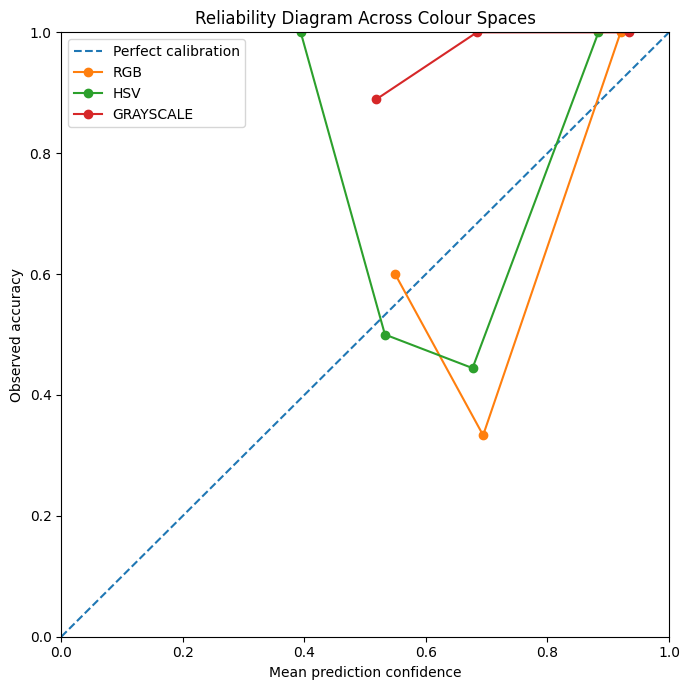

In [45]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

for color_space, results in calibration_results.items():

    bins = results["bins"]

    ax.plot(
        bins["mean_confidence"],
        bins["accuracy"],
        marker="o",
        label=color_space.upper()
    )

ax.set_title("Reliability Diagram Across Colour Spaces")
ax.set_xlabel("Mean prediction confidence")
ax.set_ylabel("Observed accuracy")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()

visualization.save_figure(
    fig,
    "reliability_diagram_seed42"
)

plt.show()
plt.close(fig)

In [46]:
calibration_path = (
    Path(config.TABLES_DIR) /
    "calibration_comparison_seed42.csv"
)

confidence_path = (
    Path(config.TABLES_DIR) /
    "prediction_confidence_comparison_seed42.csv"
)

calibration_summary.to_csv(calibration_path, index=False)
confidence_summary_df.to_csv(confidence_path, index=False)

print("Saved calibration results:", calibration_path)
print("Saved confidence results:", confidence_path)

Saved calibration results: /content/drive/MyDrive/DeepLearning/outputs/tables/calibration_comparison_seed42.csv
Saved confidence results: /content/drive/MyDrive/DeepLearning/outputs/tables/prediction_confidence_comparison_seed42.csv


## 8. Comparative Analysis

This section consolidates the experimental results across RGB, HSV, and grayscale representations. The comparison considers classification performance, computational cost, prediction confidence, and probability calibration.

The purpose is to identify differences between the colour-space representations and examine whether these differences suggest a relationship between image representation and CNN classification behaviour.

The results are interpreted as preliminary findings, given the limited test-set size and the use of a single random seed.

In [47]:
# Load the saved experiment summaries

summary_results = []

for color_space in ["rgb", "hsv", "grayscale"]:

    summary_path = (
        Path(config.METRICS_DIR)
        / f"{color_space}_seed{SEED}_experiment_summary.csv"
    )

    assert summary_path.exists(), f"Missing file: {summary_path}"

    summary = pd.read_csv(summary_path)
    summary_results.append(summary)

combined_results = pd.concat(
    summary_results,
    ignore_index=True
)

display(combined_results)

,color_space,seed,epochs_completed,best_epoch,training_time_seconds,parameter_count,accuracy,macro_precision,macro_recall,macro_f1,test_loss,test_accuracy
0,rgb,42,30,30,136.728655,110147,0.800000,0.809091,0.800000,0.803091,0.437413,0.800000
1,hsv,42,30,30,190.902518,110147,0.700000,0.695604,0.700000,0.688747,0.645840,0.700000
2,grayscale,42,30,27,124.974325,110147,0.966667,0.969697,0.966667,0.966583,0.361908,0.966667


In [48]:
comparison_results = []

for color_space in ["rgb", "hsv", "grayscale"]:

    summary = combined_results.loc[
        combined_results["color_space"] == color_space
    ].iloc[0]

    calibration = calibration_summary_df.loc[
        calibration_summary_df["color_space"] == color_space
    ].iloc[0]

    confidence = confidence_summary_df.loc[
        confidence_summary_df["color_space"] == color_space
    ].iloc[0]

    comparison_results.append({
        "color_space": color_space,
        "test_accuracy": summary["test_accuracy"],
        "macro_f1": summary["macro_f1"],
        "training_time_seconds": summary["training_time_seconds"],
        "mean_confidence": confidence["mean_confidence"],
        "ece": calibration["ece"],
        "brier_score": calibration["brier_score"]
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,color_space,test_accuracy,macro_f1,training_time_seconds,mean_confidence,ece,brier_score
0,rgb,0.8000,0.8031,136.7287,0.8133,0.131,0.2507
1,hsv,0.7000,0.6887,190.9025,0.7117,0.145,0.3825
2,grayscale,0.9667,0.9666,124.9743,0.7257,0.241,0.1998


## 9. Repeated-Seed Experiments

### 9.1 Experimental Design

To investigate the robustness of the observed results, the experiments are repeated using additional random seeds.

The original experiment used seed 42. Two additional seeds, 123 and 2026, are introduced to investigate how variations in random initialisation and training randomness influence model performance.

All experiments retain the same dataset partitions, CNN architecture, preprocessing configurations, hyperparameters, and evaluation metrics.

The experiments are conducted independently for RGB, HSV, and grayscale representations.

The repeated experiments allow performance variability to be examined across different random seeds, providing a more reliable assessment than relying on a single training run.

###9.2 Configure repeated experiments

In [49]:
# Repeated experiment configuration

REPEATED_SEEDS = [123, 2026]

COLOR_SPACES = ["rgb", "hsv", "grayscale"]

EPOCHS = config.MAX_EPOCHS

print("Repeated experiment configuration")
print("---------------------------------")
print(f"Seeds: {REPEATED_SEEDS}")
print(f"Colour spaces: {COLOR_SPACES}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Total additional experiments: {len(REPEATED_SEEDS) * len(COLOR_SPACES)}")

Repeated experiment configuration
---------------------------------
Seeds: [123, 2026]
Colour spaces: ['rgb', 'hsv', 'grayscale']
Maximum epochs: 30
Total additional experiments: 6


### 9.3 Execution of Repeated Experiments

Each colour-space experiment is repeated using the additional random seeds.

The existing experiment pipeline is reused to ensure consistency in data loading, preprocessing, model construction, training, and evaluation.

Each experiment is saved independently using its colour-space and seed identifiers.

In [50]:
# Execute repeated experiments

repeated_experiment_results = {}

for seed in REPEATED_SEEDS:

    for color_space in COLOR_SPACES:

        experiment_id = f"{color_space}_seed{seed}"

        print("\n" + "=" * 60)
        print(f"Running experiment: {experiment_id}")
        print("=" * 60)

        results = experiment.run_experiment(
            color_space=color_space,
            seed=seed,
            epochs=EPOCHS
        )

        repeated_experiment_results[experiment_id] = results

        print(f"\nCompleted: {experiment_id}")
        print(f"Test accuracy: "
              f"{results['evaluation_results']['summary']['test_accuracy']:.4f}")
        print(f"Macro F1: "
              f"{results['evaluation_results']['summary']['macro_f1']:.4f}")
        print(f"Training time: "
              f"{results['training_metadata']['training_time_seconds']:.2f} seconds")

print("\nAll repeated experiments completed.")


Running experiment: rgb_seed123
Starting experiment: RGB
Random seed: 123

Loading datasets...
Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.

Training model...
Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3676 - loss: 1.1057
Epoch 1: val_loss improved from None to 1.09748, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed123.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed123.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.3381 - loss: 1.1241 - val_accuracy: 0.3220 - val_loss: 1.0975 - learning_rate: 0.0010
Epoch 2/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.3219 - loss: 1.1124
Epoch 2: val_loss improved from 1.09748 to 1.06564, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed123.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/model

### 9.4 Consolidation of Experimental Results

The results from the repeated experiments are combined with the original experiments using seed 42.

The resulting dataset contains the evaluation metrics and training metadata for each colour-space representation across all three random seeds.

This consolidated dataset provides the basis for analysing performance variability and comparing the consistency of the different colour-space representations.

In [51]:
# Collect results from the repeated experiments

repeated_rows = []

for experiment_id, results in repeated_experiment_results.items():

    evaluation_summary = results["evaluation_results"]["summary"]
    training_metadata = results["training_metadata"]

    repeated_rows.append({
        "color_space": results["color_space"],
        "seed": results["seed"],
        "epochs_completed": training_metadata["epochs_completed"],
        "best_epoch": training_metadata["best_epoch"],
        "training_time_seconds": training_metadata["training_time_seconds"],
        "parameter_count": training_metadata["parameter_count"],
        "accuracy": evaluation_summary["accuracy"],
        "macro_precision": evaluation_summary["macro_precision"],
        "macro_recall": evaluation_summary["macro_recall"],
        "macro_f1": evaluation_summary["macro_f1"],
        "test_loss": evaluation_summary["test_loss"],
        "test_accuracy": evaluation_summary["test_accuracy"]
    })

repeated_results_df = pd.DataFrame(repeated_rows)


# Load the original seed 42 results

original_results_path = Path(config.METRICS_DIR) / "combined_experiment_results.csv"

if original_results_path.exists():

    original_results_df = pd.read_csv(original_results_path)

else:

    original_results_df = pd.concat([
        pd.read_csv(
            Path(config.METRICS_DIR) /
            f"{color_space}_seed42_experiment_summary.csv"
        )
        for color_space in COLOR_SPACES
    ], ignore_index=True)


# Combine all nine experiments

all_experiment_results = pd.concat(
    [original_results_df, repeated_results_df],
    ignore_index=True
)

all_experiment_results = all_experiment_results.sort_values(
    ["color_space", "seed"]
).reset_index(drop=True)

display(all_experiment_results.round(4))

,color_space,seed,epochs_completed,best_epoch,training_time_seconds,parameter_count,accuracy,macro_precision,macro_recall,macro_f1,test_loss,test_accuracy
0,grayscale,42,30,27,124.9743,110147,0.9667,0.9697,0.9667,0.9666,0.3619,0.9667
1,grayscale,123,30,27,92.2811,110147,0.8000,0.8222,0.8000,0.8054,0.5053,0.8000
2,grayscale,2026,30,30,90.8948,110147,0.8333,0.8424,0.8333,0.8364,0.4532,0.8333
3,hsv,42,30,30,190.9025,110147,0.7000,0.6956,0.7000,0.6887,0.6458,0.7000
4,hsv,123,27,21,82.7941,110147,0.6000,0.5861,0.6000,0.5899,0.7700,0.6000
5,hsv,2026,26,20,86.1238,110147,0.6667,0.6667,0.6667,0.6667,0.7199,0.6667
6,rgb,42,30,30,136.7287,110147,0.8000,0.8091,0.8000,0.8031,0.4374,0.8000
7,rgb,123,30,30,111.9550,110147,0.8000,0.8091,0.8000,0.8031,0.4875,0.8000
8,rgb,2026,30,26,86.8785,110147,0.7000,0.7222,0.7000,0.6932,0.5139,0.7000


### 9.5 Performance Variability Across Random Seeds

To examine the consistency of model performance, the mean and standard deviation of the evaluation metrics are calculated for each colour-space representation.

The mean provides an estimate of average performance across repeated runs, while the standard deviation indicates sensitivity to random initialisation and training randomness.

A lower standard deviation indicates more consistent performance across the evaluated seeds.

In [52]:
# Calculate mean and standard deviation across seeds

metrics_to_analyse = [
    "test_accuracy",
    "macro_f1",
    "test_loss",
    "training_time_seconds",
    "best_epoch"
]

performance_summary = (
    all_experiment_results
    .groupby("color_space")[metrics_to_analyse]
    .agg(["mean", "std"])
)

display(performance_summary.round(4))

test_accuracy         macro_f1         test_loss          \
                     mean     std     mean     std      mean     std   
color_space                                                            
grayscale          0.8667  0.0882   0.8695  0.0855    0.4401  0.0726   
hsv                0.6556  0.0509   0.6484  0.0519    0.7119  0.0625   
rgb                0.7667  0.0577   0.7665  0.0635    0.4796  0.0389   

            training_time_seconds          best_epoch          
                             mean      std       mean     std  
color_space                                                    
grayscale                102.7167  19.2881    28.0000  1.7321  
hsv                      119.9401  61.4778    23.6667  5.5076  
rgb                      111.8540  24.9252    28.6667  2.3094

### 9.6 Visual Comparison of Performance and Variability

The mean test accuracy and macro F1-score are visualised alongside their standard deviations.

Error bars represent the standard deviation across the three random seeds and illustrate the variability in model performance.

The visualisation provides a direct comparison of both average classification performance and sensitivity to training randomness.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/repeated_seed_performance_comparison.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/repeated_seed_performance_comparison.pdf


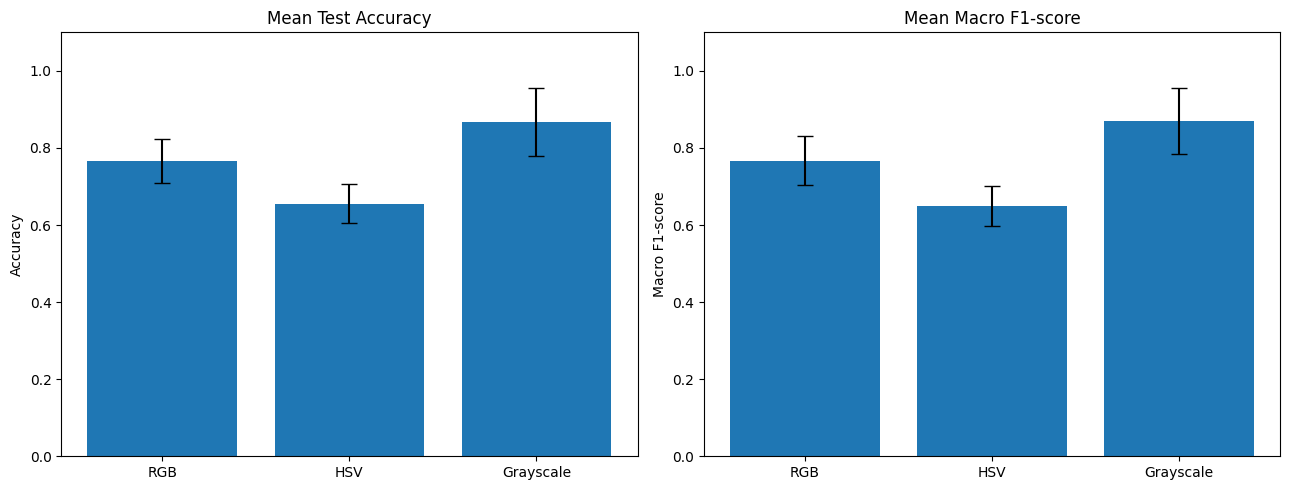

In [53]:
# Prepare mean and standard deviation for plotting

accuracy_stats = (
    all_experiment_results
    .groupby("color_space")["test_accuracy"]
    .agg(["mean", "std"])
    .reindex(["rgb", "hsv", "grayscale"])
)

f1_stats = (
    all_experiment_results
    .groupby("color_space")["macro_f1"]
    .agg(["mean", "std"])
    .reindex(["rgb", "hsv", "grayscale"])
)


# Plot accuracy and macro F1

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

color_labels = ["RGB", "HSV", "Grayscale"]
x = np.arange(len(color_labels))

axes[0].bar(
    x,
    accuracy_stats["mean"],
    yerr=accuracy_stats["std"],
    capsize=6
)

axes[0].set_title("Mean Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(x)
axes[0].set_xticklabels(color_labels)
axes[0].set_ylim(0, 1.1)

axes[1].bar(
    x,
    f1_stats["mean"],
    yerr=f1_stats["std"],
    capsize=6
)

axes[1].set_title("Mean Macro F1-score")
axes[1].set_ylabel("Macro F1-score")
axes[1].set_xticks(x)
axes[1].set_xticklabels(color_labels)
axes[1].set_ylim(0, 1.1)

plt.tight_layout()

visualization.save_figure(
    fig,
    "repeated_seed_performance_comparison"
)

plt.show()

### 9.7 Consistency of Performance Differences

To further investigate the observed performance differences, the accuracy and macro F1-score of each colour-space representation are compared across individual random seeds.

The analysis examines whether the relative performance ranking remains consistent across repeated runs.

Since all experiments use the same dataset partitions and corresponding random seeds, comparisons can be made between the results obtained under each seed.

This provides additional insight into the consistency of the observed performance differences.

In [54]:
# Compare performance across colour spaces for each seed

accuracy_by_seed = all_experiment_results.pivot(
    index="seed",
    columns="color_space",
    values="test_accuracy"
)

f1_by_seed = all_experiment_results.pivot(
    index="seed",
    columns="color_space",
    values="macro_f1"
)

print("Test accuracy by seed:")
display(accuracy_by_seed.round(4))

print("Macro F1 by seed:")
display(f1_by_seed.round(4))


# Calculate paired performance differences

seed_differences = pd.DataFrame({
    "seed": accuracy_by_seed.index,
    "grayscale_vs_rgb": (
        accuracy_by_seed["grayscale"] - accuracy_by_seed["rgb"]
    ).values,
    "grayscale_vs_hsv": (
        accuracy_by_seed["grayscale"] - accuracy_by_seed["hsv"]
    ).values,
    "rgb_vs_hsv": (
        accuracy_by_seed["rgb"] - accuracy_by_seed["hsv"]
    ).values
})

print("Accuracy differences between colour spaces:")
display(seed_differences.round(4))

Test accuracy by seed:


color_space,grayscale,hsv,rgb
seed,,,
42,0.9667,0.7000,0.8
123,0.8000,0.6000,0.8
2026,0.8333,0.6667,0.7


Macro F1 by seed:


color_space,grayscale,hsv,rgb
seed,,,
42,0.9666,0.6887,0.8031
123,0.8054,0.5899,0.8031
2026,0.8364,0.6667,0.6932


Accuracy differences between colour spaces:


,seed,grayscale_vs_rgb,grayscale_vs_hsv,rgb_vs_hsv
0,42,0.1667,0.2667,0.1000
1,123,0.0000,0.2000,0.2000
2,2026,0.1333,0.1667,0.0333


### 9.8 Summary of Repeated-Seed Experiments

The repeated-seed experiments provide additional evidence that colour-space representation influences CNN-based artistic style classification.

Grayscale achieved the highest mean test accuracy (86.67%) and macro F1-score (0.8695), outperforming RGB and HSV across the three experimental runs.

The performance ranking was consistent across all seeds when comparing RGB and HSV, with RGB achieving higher accuracy in every run. Grayscale also consistently outperformed HSV.

When compared with RGB, grayscale achieved higher accuracy in two runs and identical accuracy in one run. This indicates that its performance advantage is not equally pronounced across all random initialisations.

Grayscale exhibited the highest standard deviation in test accuracy (0.0882), suggesting greater sensitivity to training randomness than RGB (0.0577) and HSV (0.0509).

Overall, the repeated experiments support the preliminary observation that grayscale can provide a strong representation for distinguishing between the selected artistic styles. However, the small number of random seeds and limited test-set size mean that the results should be interpreted cautiously.